# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
uploaded = files.upload()

df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.emb = nn.Embedding(
            len(tokenizer.word_index) + 1,
            16,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            16,
            32,
            batch_first=True
        )

        self.att = nn.Linear(32, 1)

        self.fc = nn.Linear(
            32,
            df["answer_id"].nunique()
        )

    def forward(self, x):

        embedded = self.emb(x)

        output, _ = self.rnn(embedded)

        scores = self.att(output).squeeze(-1)

        # Ignore padding words
        scores = scores.masked_fill(x == 0, -1e9)

        weights = torch.softmax(scores, dim=1)

        context = (output * weights.unsqueeze(-1)).sum(1)

        prediction = self.fc(context)

        return prediction, weights


model = RNN()

print(model)

RNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

for epoch in range(50):

    optimizer.zero_grad()

    output, weights = model(X)

    loss = nn.functional.cross_entropy(output, y)

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

print("Training finished!")

Epoch 10, Loss: 1.9305
Epoch 20, Loss: 1.2049
Epoch 30, Loss: 0.5520
Epoch 40, Loss: 0.1980
Epoch 50, Loss: 0.0688
Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

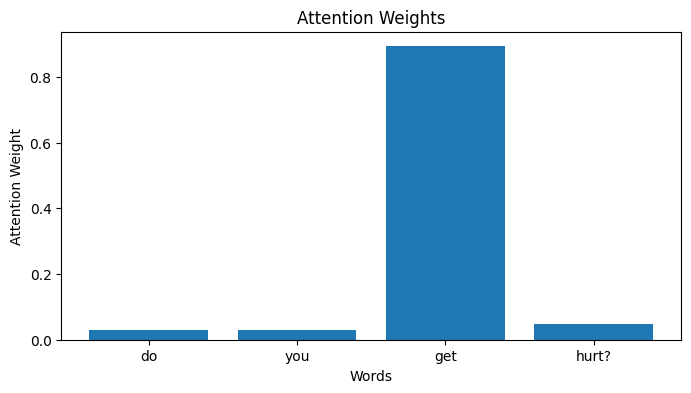

In [6]:
model.eval()

question = df["question"].iloc[0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

attention_weights = weights[0, :len(words)].tolist()

plt.figure(figsize=(8, 4))
plt.bar(words, attention_weights)

plt.title("Attention Weights")
plt.xlabel("Words")
plt.ylabel("Attention Weight")

plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Yes, the words with the highest attention weights generally appear important for understanding the question. The model focuses on meaningful words that help identify the correct answer. This shows that attention helps the model focus on relevant information.

--------------------------------
Question: do you get hurt?
Highest attention word: get
Attention weight: 0.8931488990783691


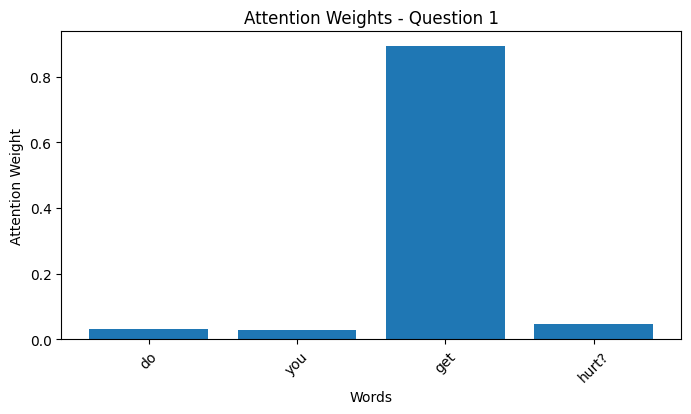

--------------------------------
Question: are you old?
Highest attention word: old?
Attention weight: 0.9187143445014954


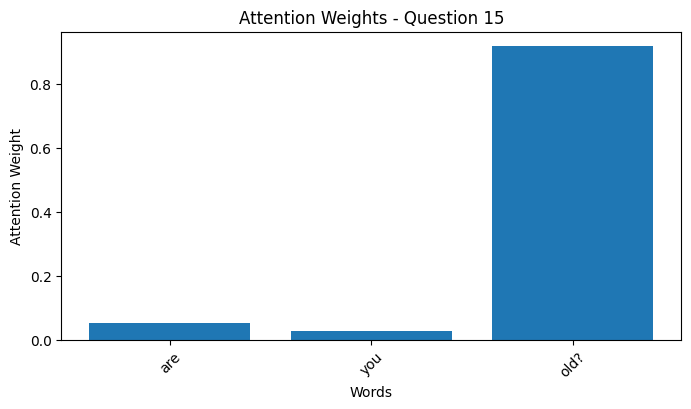

--------------------------------
Question: who programmed you?
Highest attention word: who
Attention weight: 0.42256563901901245


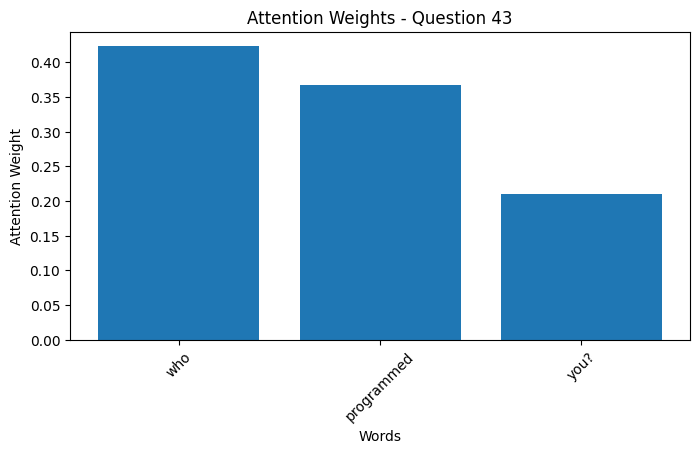

In [7]:
model.eval()

selected_questions = [0, 14, 42]

for i in selected_questions:

    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    max_index = attention_weights.index(max(attention_weights))

    print("--------------------------------")
    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("Attention weight:", attention_weights[max_index])

    plt.figure(figsize=(8, 4))

    plt.bar(words, attention_weights)

    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")

    plt.xticks(rotation=45)
    plt.show()

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

The model may focus on similar or different words when processing questions with similar meanings. It tries to identify important keywords related to the question. This suggests that attention helps the model understand relevant information even when questions are written differently.

--------------------------------
Question: how do you feel about artificial intelligence?
Highest attention word: about
Attention weight: 0.8225033283233643


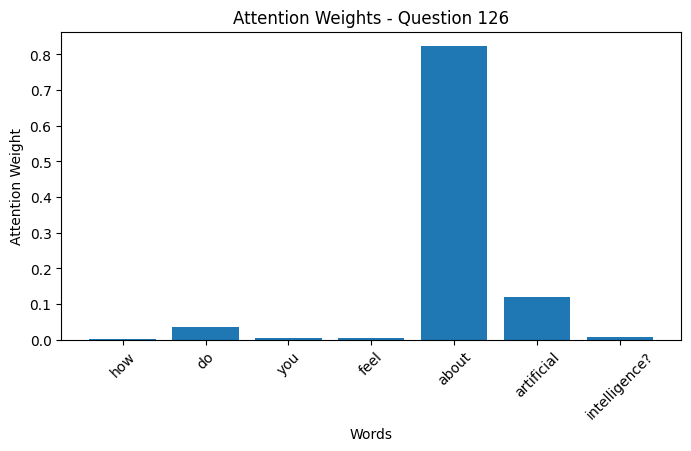

--------------------------------
Question: what do you think about ai?
Highest attention word: think
Attention weight: 0.911629855632782


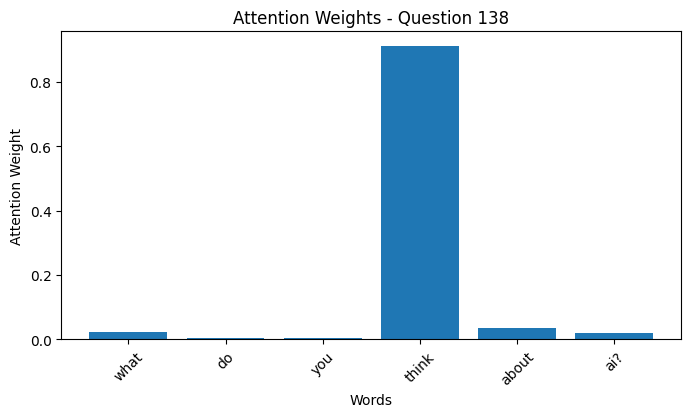

In [8]:
model.eval()

question_indices = [126, 138]

for i in question_indices:

    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    max_index = attention_weights.index(max(attention_weights))

    print("--------------------------------")
    print("Question:", question)
    print("Highest attention word:", words[max_index])
    print("Attention weight:", attention_weights[max_index])

    plt.figure(figsize=(8, 4))

    plt.bar(words, attention_weights)

    plt.title(f"Attention Weights - Question {i}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")

    plt.xticks(rotation=45)
    plt.show()